In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os#
import warnings
warnings.filterwarnings("ignore")


In [2]:


splits = {'train': 'data/train-00000-of-00001-daf190ce720b3dbb.parquet', 'test': 'data/test-00000-of-00001-fa9b3e8ade89a333.parquet'}
df = pd.read_parquet("hf://datasets/Deysi/spam-detection-dataset/" + splits["train"])

In [3]:
df.head()

,text,label
0,hey I am looking for Xray baggage datasets can...,not_spam
1,"""Get rich quick! Make millions in just days wi...",spam
2,URGENT MESSAGE: YOU WON'T BELIEVE WHAT WE HAVE...,spam
3,[Google AI Blog: Contributing Data to Deepfake...,not_spam
4,Trying to see if anyone already has timestamps...,not_spam


In [4]:
df.shape

(8175, 2)

In [5]:
df.label.value_counts()

,count
label,
spam,4125
not_spam,4050


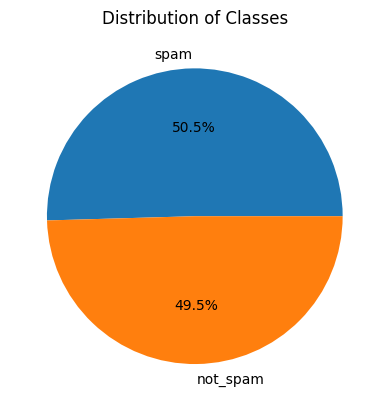

In [6]:
#Distributuon of the data
# Get the counts of each class and their names
class_dis = df.label.value_counts()
class_names = class_dis.index

plt.pie(class_dis, labels=class_names, autopct='%.1f%%')
plt.title('Distribution of Classes')
plt.show()

In [7]:
#convert the text to lower case
df["text"]=df["text"].str.lower()

In [8]:
df.head()

,text,label
0,hey i am looking for xray baggage datasets can...,not_spam
1,"""get rich quick! make millions in just days wi...",spam
2,urgent message: you won't believe what we have...,spam
3,[google ai blog: contributing data to deepfake...,not_spam
4,trying to see if anyone already has timestamps...,not_spam


In [ ]:
#replace spam with 0 and not_spam with 1
df["label"]=df["label"].replace({"spam","not_spam"},{1,0})

In [10]:
df.head()

,text,label
0,hey i am looking for xray baggage datasets can...,1
1,"""get rich quick! make millions in just days wi...",0
2,urgent message: you won't believe what we have...,0
3,[google ai blog: contributing data to deepfake...,1
4,trying to see if anyone already has timestamps...,1


In [11]:
#remove stop word
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [12]:
# def function to remove stop word
stopwords=set(stopwords.words("english"))
def remove_stopwords(text):
  token=word_tokenize(text)
  filtered_text=[
      word for word in token
      if word not in stopwords
  ]
  return " ".join(filtered_text)

In [13]:
df["filtered_text"]=df['text'].apply(remove_stopwords)

In [14]:
df.head()

,text,label,filtered_text
0,hey i am looking for xray baggage datasets can...,1,hey looking xray baggage datasets provide
1,"""get rich quick! make millions in just days wi...",0,`` get rich quick ! make millions days new rev...
2,urgent message: you won't believe what we have...,0,urgent message : wo n't believe offer ! ! ! he...
3,[google ai blog: contributing data to deepfake...,1,[ google ai blog : contributing data deepfake ...
4,trying to see if anyone already has timestamps...,1,trying see anyone already timestamps key event...


In [15]:
#remove the original text
df.drop("text",axis=1,inplace=True)

In [16]:
df.head()

,label,filtered_text
0,1,hey looking xray baggage datasets provide
1,0,`` get rich quick ! make millions days new rev...
2,0,urgent message : wo n't believe offer ! ! ! he...
3,1,[ google ai blog : contributing data deepfake ...
4,1,trying see anyone already timestamps key event...


In [17]:
df["filtered_text"][1]

"`` get rich quick ! make millions days new revolutionary system ! n't miss amazing opportunity ! ''"

In [18]:
#remove punction from text
import re
def remove_symbols(text):
    return re.sub(r'[^a-zA-Z0-9\s]', '', text)

In [19]:
df['filtered_text']=df['filtered_text'].apply(remove_symbols)

In [20]:
df.head()

,label,filtered_text
0,1,hey looking xray baggage datasets provide
1,0,get rich quick make millions days new revolu...
2,0,urgent message wo nt believe offer hey ye...
3,1,google ai blog contributing data deepfake de...
4,1,trying see anyone already timestamps key event...


In [21]:
df["filtered_text"][1]

' get rich quick  make millions days new revolutionary system  nt miss amazing opportunity  '

In [22]:
# Count words frequency in spam and not spam


In [23]:
from collections import Counter

# Split the dataset into spam and non-spam
spam_texts = df[df['label'] == 1]['filtered_text'].str.cat(sep=' ').split()
not_spam_texts = df[df['label'] == 0]['filtered_text'].str.cat(sep=' ').split()

# Count frequencies
spam_word_freq = Counter(spam_texts)
not_spam_word_freq = Counter(not_spam_texts)

# Get the 15 most common words for each category
common_spam = pd.DataFrame(spam_word_freq.most_common(15), columns=['Word', 'Frequency'])
common_not_spam = pd.DataFrame(not_spam_word_freq.most_common(15), columns=['Word', 'Frequency'])

print("--- Top 15 Words in Spam ---")
display(common_spam)
print("\n--- Top 15 Words in Non-Spam ---")
display(common_not_spam)

--- Top 15 Words in Spam ---


,Word,Frequency
0,data,3826
1,dataset,2258
2,amp,2123
3,https,2061
4,m,1615
5,would,1587
6,looking,1519
7,find,1388
8,like,1148
9,anyone,1045



--- Top 15 Words in Non-Spam ---


,Word,Frequency
0,nt,2983
1,s,2820
2,get,2649
3,amazing,1727
4,got,1651
5,social,1592
6,ve,1469
7,new,1405
8,make,1295
9,time,1141


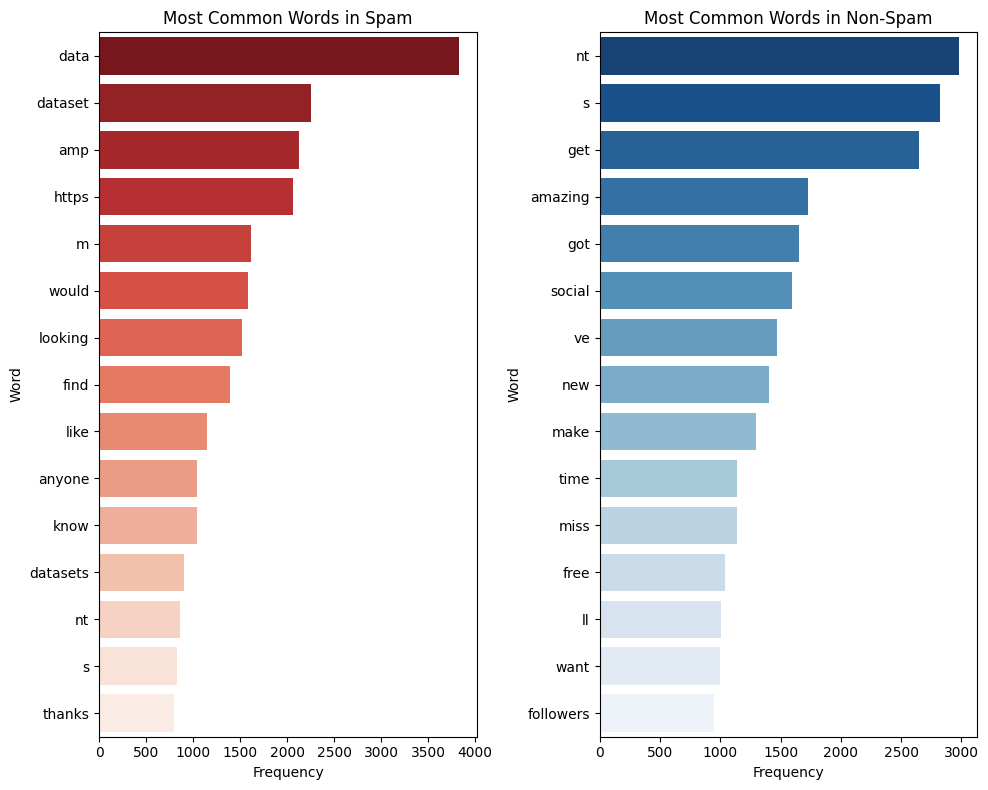

In [24]:
# Visualize word frequencies
fig, axes = plt.subplots(1, 2, figsize=(10, 8))
sns.barplot(ax=axes[0], x='Frequency', y='Word', data=common_spam, palette='Reds_r')
axes[0].set_title('Most Common Words in Spam')

sns.barplot(ax=axes[1], x='Frequency', y='Word', data=common_not_spam, palette='Blues_r')
axes[1].set_title('Most Common Words in Non-Spam')

plt.tight_layout()
plt.show()

In [25]:
#stemming and Lemmatizeing
import nltk
nltk.download("wordnet")
from nltk.stem import SnowballStemmer,WordNetLemmatizer
stemmer=SnowballStemmer("english")
lemmatizer=WordNetLemmatizer()
from nltk.tokenize import word_tokenize
def stem_and_lemmatize(text):
    words=word_tokenize(text)
    stemmed_words=[stemmer.stem(word) for word in words]
    lemmatized_words=[lemmatizer.lemmatize(word) for word in stemmed_words]
    return " ".join(lemmatized_words)

[nltk_data] Downloading package wordnet to /root/nltk_data...


In [26]:
df['filtered_text']=df['filtered_text'].apply(stem_and_lemmatize)

In [27]:
df["filtered_text"][1]

'get rich quick make million day new revolutionari system nt miss amaz opportun'

In [28]:
def remove_num(text):
  return re.sub(r'\d+','',text)

In [29]:
df['filtered_text']=df['filtered_text'].apply(remove_num)

In [30]:
df

,label,filtered_text
0,1,hey look xray baggag dataset provid
1,0,get rich quick make million day new revolution...
2,0,urgent messag wo nt believ offer hey yeah eye ...
3,1,googl ai blog contribut data deepfak detect re...
4,1,tri see anyon alreadi timestamp key event happ...
...,...,...
8170,1,hi creat dataset take pictur specif object eg ...
8171,0,deal deal deal hey peep wo nt believ amaz deal...
8172,1,hi work project need penalti conced score odd ...
8173,0,want blow social medium follow instant look am...


- Split into training and test sets
- Tokenize the training messages
- Train Word2Vec on training messages
- Convert each message into a vector

In [31]:
#split the dataset to feature and label
X=df["filtered_text"]
y=df["label"]

In [32]:
#spliting the data to train and test
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


In [33]:
#convert to token
X_train_tokens=X_train.apply(word_tokenize)
x_test_tokens=X_test.apply(word_tokenize)

In [34]:
pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 37.2 MB/s  0:00:00


In [ ]:
# Defining the word2vec parameter and fitting it to X_tain_tokken
from gensim.models import Word2Vec
w2v_model = Word2Vec(
    sentences=X_train_tokens,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=1,
    seed=42,
    epochs=10
)

In [ ]:
#Vocabulary size
len(w2v_model.wv)

In [ ]:
#similar word with free and now
print(w2v_model.wv.most_similar('free'))
print(w2v_model.wv.most_similar('now'))

In [ ]:
print(w2v_model.wv['free'])

In [ ]:
# message vectorisation - convert the token to ssentence and average the vecor
import numpy as np

def get_message_vector(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(model.wv.vector_size)

    return np.mean(vectors, axis=0)

In [ ]:
X_train_vectors = np.array([
    get_message_vector(tokens, w2v_model)
    for tokens in X_train_tokens
])

X_test_vectors = np.array([
    get_message_vector(tokens, w2v_model)
    for tokens in x_test_tokens
])

In [ ]:
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import time
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score,accuracy_score
model_chart = {
    "SVC": {
        "model": svm.SVC(),
        "param": {
            "kernel": ["rbf", "linear"],
            "C": [0.1, 2, 4,],
            "gamma": ["auto"]
        }
    },
    "rf": {
        "model": RandomForestClassifier(n_jobs=-1, random_state=42),
        "param":{
            "n_estimators": [50, 100, 200],
            "max_depth": [None, 10, 20],
            "min_samples_split": [2, 5],
            "min_samples_leaf": [1, 4]
        }
    },
    "lr": {
        "model": LogisticRegression(max_iter=1000, random_state=42),
        "param": [
            # Params for liblinear (supports l1 and l2)
            {
                "solver": ["liblinear"],
                "penalty": ["l1", "l2"],
                "C": [0.01, 0.1, 1, 10]
            }
        ]
    }
}




In [ ]:
score=[]
table_data=[]
start_time=time.perf_counter()
for model_name,mp in model_chart.items():
    ggs=GridSearchCV(mp['model'],mp['param'],cv=5,return_train_score=False,n_jobs=-1)
    ggs.fit(X_train_vectors,y_train)
    end_time=time.perf_counter()
    escalated_time=end_time-start_time

    best_param=ggs.best_params_
    best_model=ggs.best_estimator_.fit(X_train_vectors,y_train)
    prediction=best_model.predict(X_test_vectors)
    table_data.append({
        "model":model_name+" grid_search",
        "a_score":round(accuracy_score(y_test,prediction),3),
        "f_score":round(f1_score(y_test,prediction)),
        "params":best_param,
        'escalated_time':escalated_time}

    )
    score.append({
        "model":model_name,
        "params":ggs.best_params_,
        "best_score":ggs.best_score_
    })

#is it possible to use pipeline here

In [ ]:
df_table_gs=pd.DataFrame(table_data)
df_table_gs

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Best parameters for SVC were: {'C': 4, 'gamma': 'auto', 'kernel': 'linear'}
best_svc = svm.SVC(C=4, kernel='linear', gamma='auto', random_state=42)

# Fit the model on the full training vectors
best_svc.fit(X_train_vectors, y_train)

# Evaluate on test vectors
y_pred = best_svc.predict(X_test_vectors)

print("--- Classification Report ---")
print(classification_report(y_test, y_pred))



In [ ]:
#plot confusion matrix graph
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [ ]:
#saving the model
import joblib
model=joblib.dump(best_svc,'spam_model.joblib')